In [8]:
import numpy as np
import pyodbc
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
clemson_player_data = pd.read_csv("fake_player_data.csv")
clemson_player_data


,batterName,Season,PAs,SLG,OBP,ISO,wOBA,ZSwing %,Chase %,ZContact %,EV90,GB %,Barrel %,Strikeout %,Walk %
0,"Priest, Collin",2024,216,0.453,0.341,0.183,0.416,61.9,24.4,82.8,92.0,48.0,11.6,26.6,9.5
1,Synthetic Player 001,2024,148,0.374,0.424,0.091,0.423,59.0,13.1,80.2,94.9,35.0,5.2,15.5,15.9
2,Synthetic Player 002,2024,275,0.565,0.300,0.320,0.418,84.1,35.5,76.2,95.7,29.2,17.3,30.5,9.0
3,Synthetic Player 003,2024,126,0.478,0.375,0.223,0.415,54.4,27.2,81.0,98.2,39.0,4.3,18.4,9.2
4,Synthetic Player 004,2024,212,0.514,0.371,0.252,0.436,60.9,17.7,86.2,94.5,53.6,8.5,21.6,11.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Synthetic Player 095,2024,227,0.470,0.338,0.223,0.416,74.1,38.6,79.6,93.6,23.1,9.0,25.7,14.2
96,Synthetic Player 096,2024,166,0.346,0.365,0.086,0.420,62.9,14.6,81.3,92.4,40.2,8.8,14.9,15.6
97,Synthetic Player 097,2024,226,0.414,0.367,0.140,0.397,74.3,16.4,89.7,87.9,50.3,7.0,19.7,10.5
98,Synthetic Player 098,2024,127,0.437,0.351,0.187,0.402,62.7,17.7,89.9,92.5,45.9,5.9,16.9,12.0


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# Define the KPI columns for similarity analysis
kpi_columns = ['xwOBA', 'ZSwing %', 'Chase %','ZContact %', 'EV90', 'ICR', 'LD %', 'FB %']

# Check which KPI columns exist
available_kpis = [col for col in kpi_columns if col in clemson_player_data.columns]
print(f"\nKPIs found in dataset: {available_kpis}")

# Remove rows with missing KPI data
df_clean = clemson_player_data.dropna(subset=available_kpis).reset_index(drop=True)

# Identify Priest's Michigan 2024 Season
# Try different possible column name combinations
priest_michigan_mask = ((df_clean['batterName'].str.contains('Priest', case=False, na=False)) & 
(df_clean['Season'] == 2024))

priest_michigan_idx = df_clean[priest_michigan_mask].index

priest_michigan_idx = priest_michigan_idx[0]
print(df_clean.loc[priest_michigan_idx, ['batterName', 'Season'] + available_kpis])

# Extract features for all players
X = df_clean[available_kpis].values

# Standardize the features (critical for kNN distance calculations)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Get Priest's Michigan features (scaled)
priest_michigan_features = X_scaled[priest_michigan_idx].reshape(1, -1)

# Function to find k nearest neighbors
def find_k_neighbors(k):
    knn = NearestNeighbors(n_neighbors=k+1, metric='euclidean')
    knn.fit(X_scaled)
    distances, indices = knn.kneighbors(priest_michigan_features)
    
    # Skip the first result (it's Priest's Michigan Season itself)
    neighbor_indices = indices[0][1:]
    neighbor_distances = distances[0][1:]
    
    results = df_clean.iloc[neighbor_indices].copy()
    results['Distance'] = neighbor_distances
    
    return results[['batterName', 'Season', 'Distance'] + available_kpis]

# Start with k=5
print("\n" + "="*80)
print("TOP 5 MOST SIMILAR PLAYER-SeasonS TO PRIEST'S MICHIGAN 2024:")
print("="*80)
neighbors_5 = find_k_neighbors(5)
print(neighbors_5.to_string(index=False))

# Check if Priest's Clemson Season is in top 5
priest_clemson_in_5 = neighbors_5['batterName'].str.contains('Priest', case=False, na=False).any()


KPIs found in dataset: ['ZSwing %', 'Chase %', 'ZContact %', 'EV90']
batterName    Priest, Collin
Season                  2024
ZSwing %                61.9
Chase %                 24.4
ZContact %              82.8
EV90                    92.0
Name: 0, dtype: object

TOP 5 MOST SIMILAR PLAYER-SeasonS TO PRIEST'S MICHIGAN 2024:
          batterName  Season  Distance  ZSwing %  Chase %  ZContact %  EV90
Synthetic Player 078    2024  0.289450      63.0     25.5        82.0  92.5
Synthetic Player 026    2024  0.462674      62.2     23.2        80.4  92.2
Synthetic Player 017    2024  0.468173      62.5     21.4        83.7  91.7
Synthetic Player 051    2024  0.483077      60.4     24.3        83.7  93.4
Synthetic Player 052    2024  0.604637      59.2     26.3        84.2  93.2


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

def find_similar_players(player_name, season, df, kpi_columns, k=5):
  
# Filter to available KPIs
    available_kpis = [col for col in kpi_columns if col in df.columns]
    
    # Remove rows with missing KPI data
    df_clean = df.dropna(subset=available_kpis).reset_index(drop=True)
    
    # Identify target player-season
    target_mask = ((df_clean['batterName'].str.contains(player_name, case=False, na=False)) & 
        (df_clean['Season'] == season))
    
    target_idx = df_clean[target_mask].index[0]
    
    # Get target player stats
    target_stats = df_clean.loc[[target_idx], ['batterName', 'Season'] + available_kpis]
    
    # Extract and standardize features
    X = df_clean[available_kpis].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Get target player's features
    target_features = X_scaled[target_idx].reshape(1, -1)
    
    # Find k nearest neighbors
    knn = NearestNeighbors(n_neighbors=k+1, metric='euclidean')
    knn.fit(X_scaled)
    distances, indices = knn.kneighbors(target_features)
    
    # Skip first result (the player themselves)
    neighbor_indices = indices[0][1:]
    neighbor_distances = distances[0][1:]
    
    # Build results DataFrame
    results = df_clean.iloc[neighbor_indices].copy()
    results['Distance'] = neighbor_distances
    
    return target_stats, results[['batterName', 'Season', 'Distance'] + available_kpis]

# Define KPI columns
kpi_columns = ['SLG', 'OBP', 'ISO', 'wOBA', 'ZSwing %','Chase %', 'ZContact %', 'EV90', 'GB %', 'Barrel %', 'Strikeout %','Walk %']

# ========== CHANGE THESE PARAMETERS ==========
player_name = 'Synthetic Player 006'
season = 2024
k_neighbors = (5)

target_stats, similar_players = find_similar_players(player_name, season, clemson_player_data, kpi_columns, k=k_neighbors)

print("TARGET PLAYER:")
print(target_stats.to_string(index=False))
print("\nK Nearest Neighbors:")
print(similar_players.to_string(index=False))

TARGET PLAYER:
          batterName  Season   SLG   OBP   ISO  wOBA  ZSwing %  Chase %  ZContact %  EV90  GB %  Barrel %  Strikeout %  Walk %
Synthetic Player 006    2024 0.428 0.342 0.124 0.432      51.8     13.1        81.3  89.2  35.7       8.2         14.0    12.8

K Nearest Neighbors:
          batterName  Season  Distance   SLG   OBP   ISO  wOBA  ZSwing %  Chase %  ZContact %  EV90  GB %  Barrel %  Strikeout %  Walk %
Synthetic Player 054    2024  1.972439 0.425 0.353 0.098 0.428      54.9     18.0        83.1  90.0  48.1       6.2          9.8    13.4
Synthetic Player 077    2024  2.344044 0.401 0.382 0.106 0.427      51.8     18.1        85.3  93.0  39.1       7.8         18.2    14.2
Synthetic Player 046    2024  2.413230 0.370 0.374 0.080 0.429      52.2     16.3        81.3  88.5  23.6       5.2         14.1    14.9
Synthetic Player 065    2024  2.538827 0.431 0.357 0.154 0.431      53.8     20.3        85.6  90.2  40.5       5.5         21.2    17.1
Synthetic Player 050    

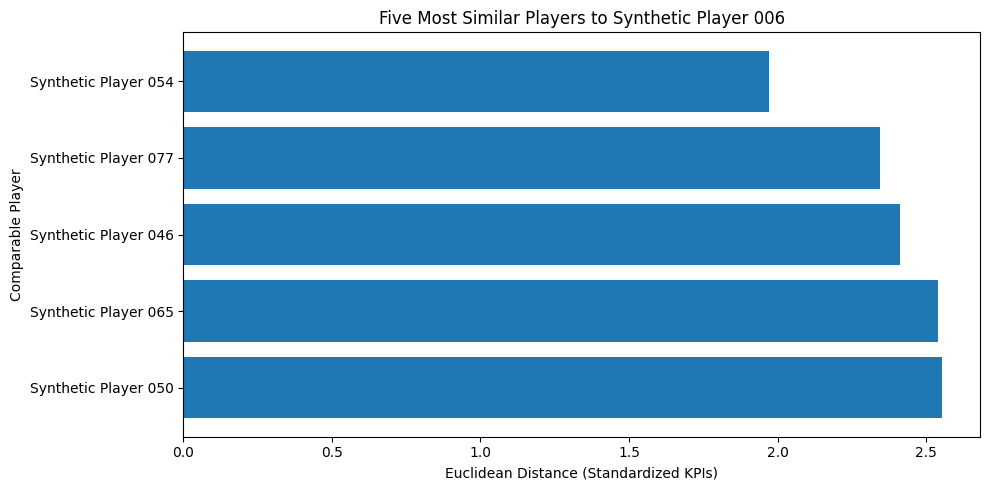

In [12]:

# Sort players from most similar to least similar
plot_data = similar_players.sort_values("Distance", ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(plot_data["batterName"], plot_data["Distance"])

plt.xlabel("Euclidean Distance (Standardized KPIs)")
plt.ylabel("Comparable Player")
plt.title(f"Five Most Similar Players to {player_name}")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


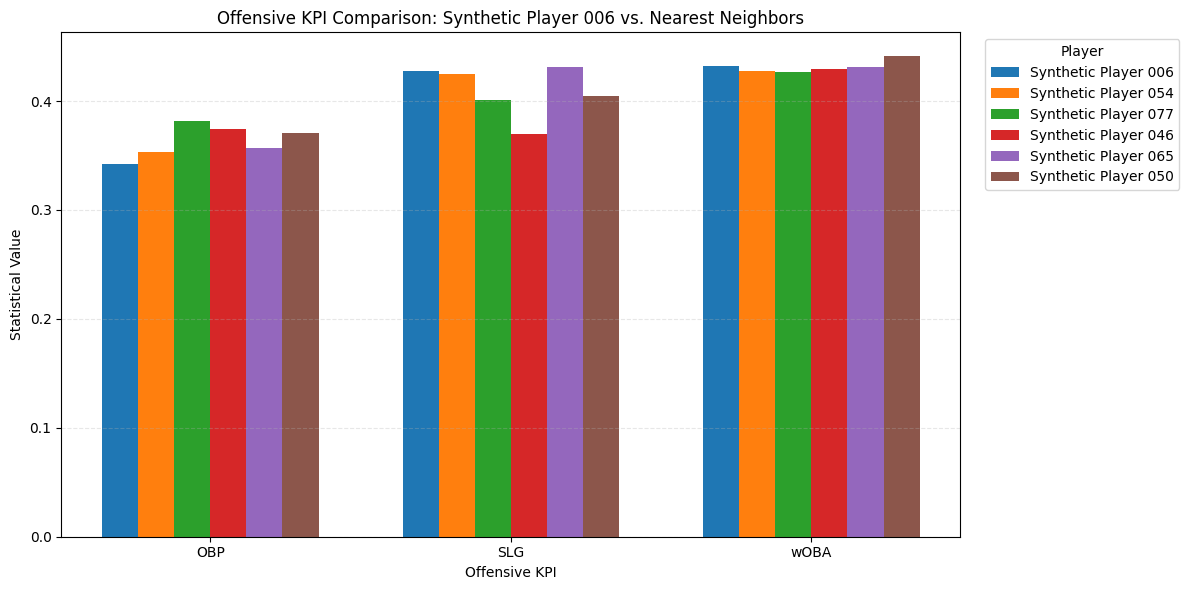

In [ ]:

# Choose the KPIs to compare
comparison_kpis = ['OBP', 'SLG', 'wOBA']

# Get the target player's statistics
target_row = target_stats.iloc[0]

# Combine target player and comparable players
player_names = [player_name] + similar_players['batterName'].tolist()

comparison_data = [target_row[comparison_kpis].astype(float).values]

for _, row in similar_players.iterrows():
    comparison_data.append(row[comparison_kpis].astype(float).values)

comparison_df = pd.DataFrame(comparison_data,columns=comparison_kpis,index=player_names)

# Create grouped bar chart
x = np.arange(len(comparison_kpis))
bar_width = 0.12

fig, ax = plt.subplots(figsize=(12, 6))

for i, player in enumerate(comparison_df.index):
    offset = (i - (len(comparison_df.index) - 1) / 2) * bar_width

    ax.bar(x + offset,
        comparison_df.loc[player].values,
        bar_width,
        label=player)

ax.set_xlabel('Offensive KPI')
ax.set_ylabel('Statistical Value')
ax.set_title(f'Offensive KPI Comparison: {player_name} vs. Nearest Neighbors')
ax.set_xticks(x)
ax.set_xticklabels(comparison_kpis)
ax.legend(title='Player', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()
